# Lesson 18 - How far away is the ship? 250 m buckets and a regression, classical models only

Lesson 12 estimated the distance with the older mel-band features and the dataset's own folds. Here the same
question uses everything since: lesson 13's engineered features, folds and test ships, and gradient boosting only.

- **One classifier for 250 m buckets** (0-250 m, 250-500 m, ..., 1,750-2,000 m), scored three ways:
  **exact** (right bucket), **near** (right or next bucket: an answer of 750-1,000 m for a ship at 600 m counts as
  correct), and **500 m buckets** (pairs of 250 m buckets added together, from the same model).
- **One regression model** that predicts the distance in metres, also turned into buckets for comparison.
- Which features: all 144 engineered numbers, or with the MFCCs cut to 1-8. The validation folds decide.

Only ship clips: background has no distance. Every bucket counts the same in training, and inside a bucket every
ship the same (as the classes in lesson 13).

```
python src/distance_classical.py      # -> runs/distance_classical/ (CPU, about 20 minutes)
```

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
import distance_classical as DC
import six_classes as S

OUT = DC.OUT_DIR
summary = json.loads((OUT / "results.json").read_text())
preds = pd.read_parquet(OUT / "predictions.parquet")
choice = pd.read_csv(OUT / "feature_choice.csv")
COLORS = dict(zip(S.CLASSES6, ["#7f7f7f", "#2a78d6", "#1baf7a", "#eb6834", "#9b59b6", "#c0392b"]))
pd.set_option("display.width", 160)

## 1. The distances

Distance from the hydrophone at the middle of each clip (from the ships' AIS positions). Few clips are closer than
250 m; most ships are 500-2,000 m away.

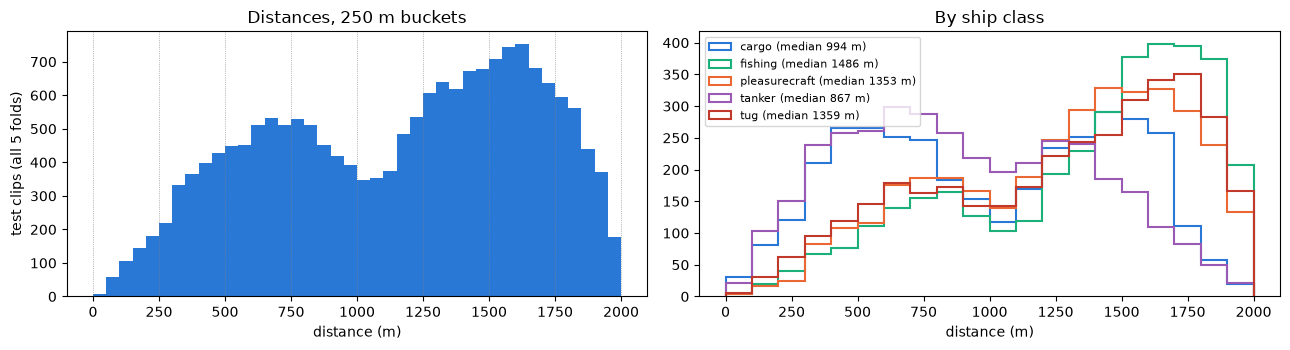

       0-250 m  250-500 m  500-750 m  750-1000 m  1000-1250 m  1250-1500 m  1500-1750 m  1750-2000 m
clips      495       1739       2452        2301         2095         3213         3522         2146


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].hist(preds.true_m, bins=np.arange(0, 2001, 50), color="#2a78d6")
for b in range(0, 2001, DC.WIDTH):
    ax[0].axvline(b, color="grey", lw=0.5, ls=":")
ax[0].set_xlabel("distance (m)"); ax[0].set_ylabel("test clips (all 5 folds)"); ax[0].set_title("Distances, 250 m buckets")
for c in S.CLASSES6[1:]:
    d = preds[preds.label == c].true_m
    ax[1].hist(d, bins=np.arange(0, 2001, 100), histtype="step", lw=1.5, color=COLORS[c], label=f"{c} (median {d.median():.0f} m)")
ax[1].set_xlabel("distance (m)"); ax[1].set_title("By ship class"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(preds.groupby("true_bucket").size().set_axis(DC.BUCKETS).rename("clips").to_frame().T)

## 2. Which features

Mean over the 5 validation folds (models trained on the training folds only):

In [3]:
m = choice.groupby("features")[["n_features", "val_exact_balanced", "val_mae_m"]].mean()
print(m.assign(val_exact_balanced=(100 * m.val_exact_balanced).round(1), val_mae_m=m.val_mae_m.round(0)))
print(f"\nchosen: {summary['chosen_features']} ({summary['n_features']} numbers) - the fewest numbers within half a "
      "point of the best validation score")

                     n_features  val_exact_balanced  val_mae_m
features                                                      
MFCC 1-8 + the rest       111.0                36.5      218.0
all engineered            144.0                37.2      219.0

chosen: all engineered (144 numbers) - the fewest numbers within half a point of the best validation score


**All 144 numbers win:** cutting the MFCCs to 1-8 costs 0.7 points on validation, more than the half point
allowed, so the full set is used. The mean error in metres is the same for both (218-219 m on validation).

## 3. The classifier: 250 m buckets

Test folds, mean ± spread over the 5 folds. "Balanced" = every true bucket counts the same (the rare 0-250 m
bucket as much as the common 1,500-1,750 m one); the other numbers are the plain share of clips.

                         classifier (250 m buckets) regression, then bucketed
exact bucket                             32.8 ± 2.3                31.5 ± 1.7
exact bucket (balanced)                  37.4 ± 2.3                32.1 ± 2.5
exact or next bucket                     69.9 ± 1.5                75.2 ± 0.7
exact or next (balanced)                 71.9 ± 1.2                74.5 ± 0.8
500 m bucket                             54.0 ± 1.5                52.7 ± 1.3
500 m bucket (balanced)                  55.5 ± 1.7                52.7 ± 1.7


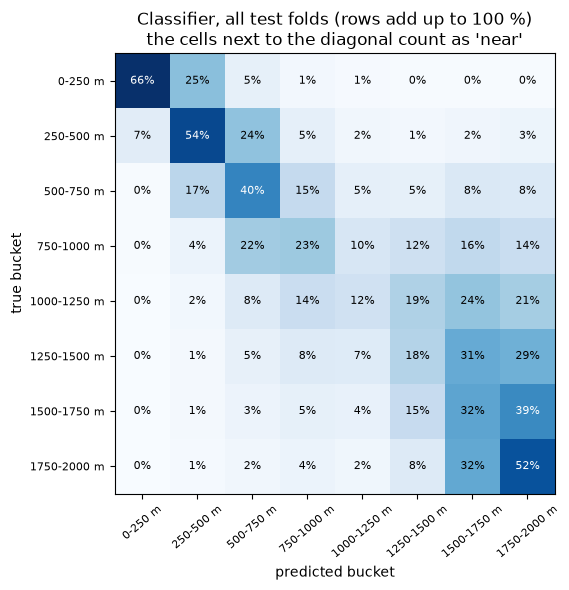

In [4]:
def table_of(key):
    df = pd.DataFrame([r[key] for r in summary["results"]])
    return (100 * df.mean()).round(1).astype(str) + " ± " + (100 * df.std()).round(1).astype(str)


scores = pd.DataFrame({"classifier (250 m buckets)": table_of("classifier"),
                       "regression, then bucketed": table_of("regression_binned")})
scores.index = ["exact bucket", "exact bucket (balanced)", "exact or next bucket", "exact or next (balanced)",
                "500 m bucket", "500 m bucket (balanced)"]
print(scores)

cm = confusion_matrix(preds.true_bucket, preds.clf_bucket, labels=range(DC.N_BUCKETS), normalize="true")
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=0.6)
for i in range(DC.N_BUCKETS):
    for j in range(DC.N_BUCKETS):
        ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > 0.35 else "black")
ax.set_xticks(range(DC.N_BUCKETS), DC.BUCKETS, rotation=40, fontsize=8)
ax.set_yticks(range(DC.N_BUCKETS), DC.BUCKETS, fontsize=8)
ax.set_xlabel("predicted bucket"); ax.set_ylabel("true bucket")
ax.set_title("Classifier, all test folds (rows add up to 100 %)\nthe cells next to the diagonal count as 'near'")
plt.tight_layout(); plt.show()

- **The exact 250 m bucket is hard:** right for 32.8 % of the clips (37.4 % balanced), against 12.5 % by
  chance. Near ships are easiest: 66 % of the clips under 250 m and 54 % at 250-500 m land in the right bucket.
- **Counting the next bucket as correct, about 70 % are right** (classifier 69.9 %, balanced 71.9 %); the
  regression, put into buckets afterwards, does better here: **75.2 %** (74.5 % balanced), with the smallest
  fold-to-fold spread (± 0.7).
- **500 m buckets: 54-56 % right** (four buckets, chance 25 %).
- **The middle distances are the hardest** (750-1,250 m: 12-23 % exact). Beyond about 1,000 m the sound changes
  little with distance, so the far buckets blur into each other.

## 4. The regression: distance in metres

test folds, mean ± spread:
  mae_m             258.10 ± 8.16 m
  median_error_m    204.25 ± 12.17 m
  within_250m        58.22 ± 2.02 %
  r2                  0.54 ± 0.02


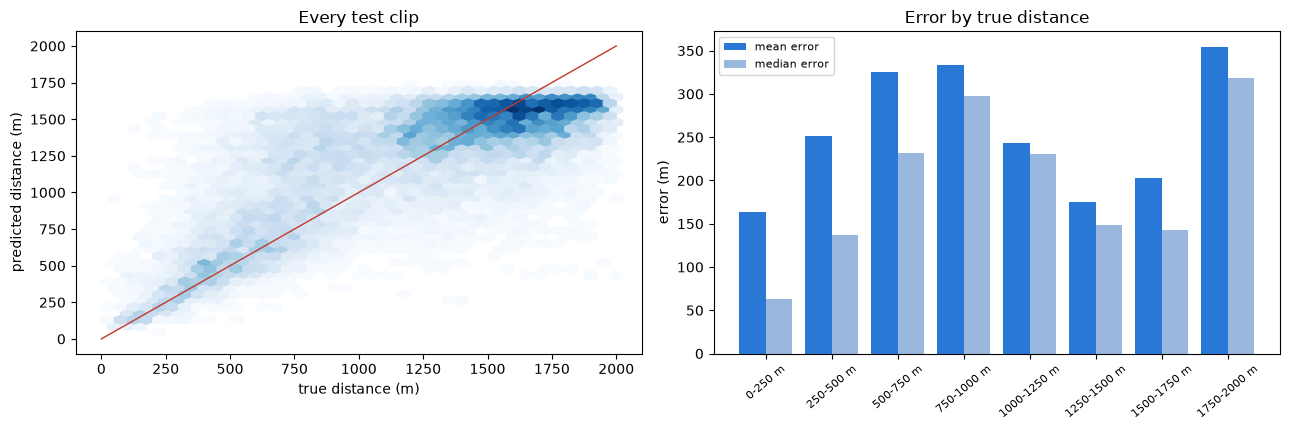

mean error by ship class (m):
label  cargo  fishing  pleasurecraft  tanker    tug
err    192.0    301.0          328.0   176.0  294.0


In [5]:
reg = pd.DataFrame([r["regression"] for r in summary["results"]])
print("test folds, mean ± spread:")
for c, unit in [("mae_m", " m"), ("median_error_m", " m"), ("within_250m", ""), ("r2", "")]:
    v = reg[c] * (100 if c == "within_250m" else 1)
    print(f"  {c:16s} {v.mean():7.2f} ± {v.std():.2f}{unit if c != 'within_250m' else ' %'}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
ax[0].hexbin(preds.true_m, preds.reg_m, gridsize=40, cmap="Blues", mincnt=1, extent=(0, 2000, 0, 2000))
ax[0].plot([0, 2000], [0, 2000], color="#c0392b", lw=1)
ax[0].set_xlabel("true distance (m)"); ax[0].set_ylabel("predicted distance (m)"); ax[0].set_title("Every test clip")
err = (preds.reg_m - preds.true_m).abs()
by = preds.assign(err=err).groupby("true_bucket").err.agg(["mean", "median"])
ax[1].bar(np.arange(DC.N_BUCKETS) - 0.2, by["mean"], 0.4, color="#2a78d6", label="mean error")
ax[1].bar(np.arange(DC.N_BUCKETS) + 0.2, by["median"], 0.4, color="#9ab8de", label="median error")
ax[1].set_xticks(range(DC.N_BUCKETS), DC.BUCKETS, rotation=40, fontsize=8)
ax[1].set_ylabel("error (m)"); ax[1].set_title("Error by true distance"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print("mean error by ship class (m):")
print(preds.assign(err=err).groupby("label").err.mean().round(0).to_frame().T)

- **Mean error 258 ± 8 m, median 204 m; 58 % of the clips are within 250 m** of the true distance (R² = 0.54).
- **The model squeezes the far end:** it rarely predicts more than about 1,700 m, so ships at 1,750-2,000 m are
  placed too close (mean error 354 m), and middle distances are pulled towards the common far values.
- **Big ships are easier** (cargo 192 m, tanker 176 m mean error) than small boats (fishing 301 m, pleasure craft
  328 m, tug 294 m). A loud big ship is heard clearly at every distance; a quiet small boat far away is close to
  the background noise.

## 5. What it means

| Test folds (mean of 5) | Exact 250 m bucket | Exact or next bucket | 500 m bucket | Mean error |
|---|---|---|---|---|
| classifier, 250 m buckets | **32.8 %** | 69.9 % | **54.0 %** | |
| regression, then bucketed | 31.5 % | **75.2 %** | 52.7 % | **258 m** |

- **If "next bucket" counts as correct, use the regression:** 75.2 % right, the steadiest across folds, and it
  also gives a number in metres. The classifier is slightly better only for the exact bucket.
- **All 144 engineered numbers** are used: fewer MFCCs did slightly worse on validation.
- **Better than lesson 12** (fold 1, mel-band features): exact 250 m bucket 32.8 % against 29.3 %, right or next
  75.2 % against 70.2 %, mean error 258 m against about 274 m.
- **What limits it:** loudness falls with distance, but it also depends on how loud the ship itself is. A big
  tanker far away can sound like a small boat close by. That is why big ships are placed better (about 180 m mean
  error) than small boats (about 300 m), and why the far distances blur together.